# Fig. 3 panel f/j carrier-seeded neighborhood maps — plotnine style

This notebook matches the carrier-seeded neighborhood logic from `ipsc-ec.Hippo.figure.ipynb` and now also matches the **plotnine UMAP plotting style** from that notebook.

Key plotting choices copied from the previous notebook:

- grey all-cell background on the shared D0–D3 UMAP
- carrier-seeded neighborhoods colored by local enrichment log2OR
- red/white/blue diverging color scale
- `coord_equal` with common x/y limits
- optional size/FDR-outline style matching the older single-gene plots
- Illustrator-friendly SVG/PDF export with editable text

Run this notebook cell-by-cell on Sherlock.



## 1. Editable configuration

The paths below were extracted from your uploaded `ipsc-ec.Hippo.figure.ipynb`. Update `GUIDE_METADATA_TSV` if the relative path is not valid from the notebook working directory.


In [14]:

from pathlib import Path

class cfg:
    # Extracted from uploaded notebook
    ADATA_H5AD = "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad"
    CNMF_USAGE_TXT = "/oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.usages.k_50.dt_0_2.consensus.txt"

    # The notebook used this as a relative path. Change to absolute path if needed.
    GUIDE_METADATA_TSV = "300genes_guide_metadata_v43.tsv"

    OUTDIR = "fig3_carrierseeded_neighborhood_outputs"

    # AnnData keys / columns
    DAY_COL = "day"
    CELLTYPE_COL = "cell_type"
    GUIDE_NAMES_KEY = "guide_names"
    GUIDE_ASSIGNMENT_KEY = "guide_assignment"
    UMAP_KEY = "X_umap"
    CNMF_KEY = "cnmf_usage"

    # Guide metadata columns
    GUIDE_ID_COL = "guide_id"
    TARGET_COL_CANDIDATES = ["putative_target_genes", "intended_target_name", "target", "target_name", "gene"]

    # Panel target lists
    PANEL_F_TARGETS = ["ACVR2A", "BMPR1A", "SMAD1", "SMAD5"]
    PANEL_J_TARGETS = ["ETV2", "HAND1", "PRKCD", "PLCG1"]

    # Controls
    CONTROL_TARGET = "non-targeting_control"
    CONTROL_PATTERNS = [
        r"non[-_ ]?target",
        r"non[-_ ]?targeting",
        r"\bntc\b",
        r"negative",
        r"neg[-_ ]?ctrl",
        r"scram",
        r"scrambled",
        r"safe",
        r"aavs1",
        r"control",
    ]

    # KNN neighborhood settings matching the uploaded notebook section
    PROGRAMS_FOR_KNN = None  # None = all cNMF programs
    CNMF_TRANSFORM = "zscore"
    K = 300
    PSEUDOCOUNT = 0.5
    RESTRICT_NEIGHBORS_TO_SAME_DAY = True
    SAME_DAY_BASELINE = True
    MODE = "all_carriers"
    DAYS_TO_USE = ["d0", "d1", "d2", "d3"]
    LOG2FC_CLIP = 3.0
    RANDOM_SEED = 1
    EXPORT_NEIGHBOR_MEMBERSHIP = False

    # Plot settings copied from previous plotnine UMAP-neighborhood notebook
    MAX_BACKGROUND_CELLS = 60000
    RANDOM_SEED_PLOT = 17

    # Two options:
    #   "simple_color" = just local-enrichment color, matching the later simplified plots
    #   "size_fdr"     = fill color + carrier-fraction size + black FDR outline
    PLOT_STYLE = "simple_color"

    LOG2OR_CLIP = 2.0
    LOG2FC_CLIP = 3.0

    BACKGROUND_POINT_SIZE = 0.10
    FOREGROUND_POINT_SIZE = 1.00
    #FACET_BACKGROUND_POINT_SIZE = 0.13
    #FACET_FOREGROUND_POINT_SIZE = 1.70

    FACET_BACKGROUND_POINT_SIZE = 0.005
    FACET_FOREGROUND_POINT_SIZE = 0.02

    # For size_fdr style
    SIZE_RANGE = (0.4, 3.5)
    SIZE_BREAKS = [2, 5, 10, 20, 30]

    CMAP_LOW = "#053061"
    CMAP_MID = "#F7F7F7"
    CMAP_HIGH = "#67001F"

    # Panel figure sizes
    FIGSIZE_SINGLE = (7.2, 6.3)
    FIGSIZE_FACET_4 = (8.2, 7.0)

    # Rasterize background only. Foreground/text remain editable in SVG/PDF.
    RASTERIZE_BACKGROUND_FOR_SPEED = True

OUTDIR = Path(cfg.OUTDIR)
OUTDIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTDIR.resolve())
print("adata:", cfg.ADATA_H5AD)
print("cNMF usage:", cfg.CNMF_USAGE_TXT)
print("guide metadata:", cfg.GUIDE_METADATA_TSV)


Output directory: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/fig3_carrierseeded_neighborhood_plotnine_style_notebook_package/fig3_carrierseeded_neighborhood_outputs
adata: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
cNMF usage: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.usages.k_50.dt_0_2.consensus.txt
guide metadata: 300genes_guide_metadata_v43.tsv


## 2. Imports

In [15]:

import os
import re
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Image, Markdown

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "svg.fonttype": "none",   # preserve text as editable text in SVG
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
})

CONTROL_TARGET = cfg.CONTROL_TARGET

# Plotnine imports for publication-style UMAP panels
from plotnine import (
    ggplot, aes, geom_point, facet_wrap,
    scale_color_gradient2, scale_fill_gradient2, scale_size_continuous,
    coord_equal, labs,
    theme_bw, theme,
    element_text, element_blank, element_rect
)
from matplotlib import font_manager

# Pick a publication/Illustrator-friendly font if available.
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT_CANDIDATES = ["Arial", "Helvetica", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"]
AI_FONT = next((f for f in FONT_CANDIDATES if f in available_fonts), "DejaVu Sans")
print("Using font for plotnine outputs:", AI_FONT)

mpl.rcParams.update({
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [AI_FONT, "DejaVu Sans"],
    "savefig.transparent": False,
})


Using font for plotnine outputs: DejaVu Sans


## 3. Helper functions: guide/target parsing and assignment

In [16]:

def looks_control(x):
    s = str(x).lower()
    return any(re.search(p, s) for p in cfg.CONTROL_PATTERNS)


def clean_target_string(x):
    if pd.isna(x):
        return []
    s = str(x).strip()
    if s.lower() in ["", "nan", "none", "na"]:
        return []
    s = s.replace("[", "").replace("]", "").replace("'", "").replace('"', "")
    parts = re.split(r"[;,|/]+", s)
    return [p.strip() for p in parts if p.strip()]


def canonical_guide_id(x):
    return str(x).strip().replace(" ", "")


def clean_day(x):
    s = str(x).strip().lower()
    if s in ["0", "d0", "day0", "day 0"]:
        return "d0"
    if s in ["1", "d1", "day1", "day 1"]:
        return "d1"
    if s in ["2", "d2", "day2", "day 2"]:
        return "d2"
    if s in ["3", "d3", "day3", "day 3"]:
        return "d3"
    return s


def get_guide_assignment_matrix(adata):
    ga = adata.obsm[cfg.GUIDE_ASSIGNMENT_KEY]
    if sparse.issparse(ga):
        return ga.tocsr().astype(bool)
    return np.asarray(ga).astype(bool)


def any_guides_per_cell(guide_assignment, guide_indices):
    if len(guide_indices) == 0:
        return np.zeros(guide_assignment.shape[0], dtype=bool)
    if sparse.issparse(guide_assignment):
        return np.asarray(guide_assignment[:, guide_indices].sum(axis=1)).ravel() > 0
    return guide_assignment[:, guide_indices].any(axis=1)


def choose_target_col(meta):
    for col in cfg.TARGET_COL_CANDIDATES:
        if col in meta.columns:
            return col
    raise ValueError(f"None of TARGET_COL_CANDIDATES found in metadata. Columns={meta.columns.tolist()}")


def load_guide_target_from_metadata(adata):
    guide_names = list(map(str, adata.uns[cfg.GUIDE_NAMES_KEY]))
    guide_name_to_idx = {g: i for i, g in enumerate(guide_names)}

    meta = pd.read_csv(cfg.GUIDE_METADATA_TSV, sep="\t")
    if cfg.GUIDE_ID_COL not in meta.columns:
        raise ValueError(f"{cfg.GUIDE_ID_COL!r} missing from {cfg.GUIDE_METADATA_TSV}")
    target_col = choose_target_col(meta)
    print(f"Using metadata target column: {target_col}")

    meta = meta[[cfg.GUIDE_ID_COL, target_col]].copy()
    meta.columns = ["guide_id", "target_entry"]
    meta["guide_id"] = meta["guide_id"].astype(str)

    meta["guide_index"] = meta["guide_id"].map(guide_name_to_idx)
    meta["match_method"] = np.where(meta["guide_index"].notna(), "exact_guide_id_match", None)

    # fallback: match after removing spaces
    if meta["guide_index"].isna().any():
        canonical_to_guide = {}
        duplicated = set()
        for g in guide_names:
            cg = canonical_guide_id(g)
            if cg in canonical_to_guide:
                duplicated.add(cg)
            else:
                canonical_to_guide[cg] = g
        for cg in duplicated:
            canonical_to_guide.pop(cg, None)
        for idx in meta.index[meta["guide_index"].isna()]:
            cg = canonical_guide_id(meta.at[idx, "guide_id"])
            if cg in canonical_to_guide:
                matched = canonical_to_guide[cg]
                meta.at[idx, "guide_index"] = guide_name_to_idx[matched]
                meta.at[idx, "match_method"] = "canonical_guide_id_match"

    mapped = meta[meta["guide_index"].notna()].copy()
    mapped["guide_index"] = mapped["guide_index"].astype(int)
    mapped["guide_name"] = [guide_names[i] for i in mapped["guide_index"]]

    records = []
    for _, row in mapped.iterrows():
        targets = clean_target_string(row["target_entry"])
        if looks_control(row["guide_name"]) or looks_control(row["target_entry"]):
            targets = [CONTROL_TARGET]
        for target in targets:
            records.append({
                "guide_index": int(row["guide_index"]),
                "guide_name": str(row["guide_name"]),
                "target_name": str(target),
                "raw_target_entry": row["target_entry"],
                "match_method": row["match_method"],
            })
    guide_target = pd.DataFrame(records).drop_duplicates()
    guide_target.to_csv(OUTDIR / "guide_to_target_map_from_300genes_metadata.csv", index=False)

    print("Guide metadata mapping QC")
    print(f"adata guide columns: {len(guide_names):,}")
    print(f"metadata guide rows: {len(meta):,}")
    print(f"metadata rows matched to adata: {mapped['guide_id'].nunique():,}")
    print(f"expanded guide-target rows: {len(guide_target):,}")
    print(f"unique mapped targets: {guide_target['target_name'].nunique():,}")
    return guide_target


def build_target_assignment(adata, guide_target):
    guide_assignment = get_guide_assignment_matrix(adata)
    if guide_assignment.shape[1] != len(adata.uns[cfg.GUIDE_NAMES_KEY]):
        raise ValueError("guide_assignment column count does not match guide_names length")

    series_by_target = {}
    target_to_guide_indices = {}
    for target, sub in guide_target.groupby("target_name"):
        idx = sorted(set(sub["guide_index"].astype(int).tolist()))
        target_to_guide_indices[target] = idx
        series_by_target[target] = any_guides_per_cell(guide_assignment, idx)

    target_assignment = pd.DataFrame(series_by_target, index=adata.obs_names).astype(bool)

    if CONTROL_TARGET not in target_assignment.columns:
        control_like = [c for c in target_assignment.columns if looks_control(c)]
        if len(control_like) == 0:
            raise ValueError("No non-targeting/control guides found")
        target_assignment[CONTROL_TARGET] = target_assignment[control_like].any(axis=1)

    carrier_counts = pd.DataFrame({
        "target": target_assignment.columns,
        "n_carrier_cells": target_assignment.sum(axis=0).astype(int).values,
        "n_guides": [len(target_to_guide_indices.get(t, [])) for t in target_assignment.columns],
    }).sort_values("n_carrier_cells", ascending=False)
    carrier_counts.to_csv(OUTDIR / "target_carrier_counts.csv", index=False)
    print("Control carrier cells:", int(target_assignment[CONTROL_TARGET].sum()))
    return target_assignment, target_to_guide_indices


## 4. Helper functions: cNMF KNN representation and base inputs

In [17]:

def load_or_make_cnmf_usage(adata):
    if cfg.CNMF_KEY in adata.obsm:
        usage = adata.obsm[cfg.CNMF_KEY]
        if isinstance(usage, pd.DataFrame):
            df = usage.copy()
        else:
            df = pd.DataFrame(np.asarray(usage), index=adata.obs_names)
            df.columns = [f"Program {i}" for i in range(df.shape[1])]
        return df

    print("Loading cNMF usage:", cfg.CNMF_USAGE_TXT)
    usage_df = pd.read_csv(cfg.CNMF_USAGE_TXT, sep="\t", index_col=0)
    usage_aligned = usage_df.reindex(adata.obs_names).fillna(0)
    usage_aligned.columns = [f"Program {i}" for i in range(usage_aligned.shape[1])]
    adata.obsm[cfg.CNMF_KEY] = usage_aligned
    return usage_aligned


def make_cnmf_knn_matrix(program_df):
    if cfg.PROGRAMS_FOR_KNN is None:
        cols = list(program_df.columns)
    else:
        cols = []
        for p in cfg.PROGRAMS_FOR_KNN:
            col = f"Program {int(p)}"
            if col not in program_df.columns:
                raise KeyError(f"{col} not found in cNMF usage columns")
            cols.append(col)
    X = program_df[cols].values.astype(float)
    if cfg.CNMF_TRANSFORM == "zscore":
        X = StandardScaler(with_mean=True, with_std=True).fit_transform(X)
    elif cfg.CNMF_TRANSFORM == "clr_zscore":
        X = np.log1p(X / np.maximum(X.sum(axis=1, keepdims=True), 1e-12))
        X = StandardScaler(with_mean=True, with_std=True).fit_transform(X)
    elif cfg.CNMF_TRANSFORM in [None, "none"]:
        pass
    else:
        raise ValueError(f"Unknown CNMF_TRANSFORM={cfg.CNMF_TRANSFORM}")
    pd.DataFrame({"program_column_used": cols}).to_csv(OUTDIR / "cnmf_programs_used_for_knn.csv", index=False)
    print(f"Using {len(cols)} cNMF programs for KNN; transform={cfg.CNMF_TRANSFORM}")
    return X, cols


def prepare_base_inputs(adata):
    adata_use = adata.copy()
    if not adata_use.obs_names.is_unique:
        adata_use.obs_names_make_unique()

    adata_use.obs["day_clean"] = adata_use.obs[cfg.DAY_COL].map(clean_day)
    if cfg.CELLTYPE_COL in adata_use.obs.columns:
        adata_use.obs["cell_type_clean"] = adata_use.obs[cfg.CELLTYPE_COL].astype(str)
    else:
        adata_use.obs["cell_type_clean"] = "unknown"

    guide_target = load_guide_target_from_metadata(adata_use)
    target_assignment, _ = build_target_assignment(adata_use, guide_target)

    guide_assignment = get_guide_assignment_matrix(adata_use)
    adata_use.obs["n_total_guides"] = (
        np.asarray(guide_assignment.sum(axis=1)).ravel()
        if sparse.issparse(guide_assignment)
        else guide_assignment.sum(axis=1)
    ).astype(int)
    targeting_cols = [c for c in target_assignment.columns if c != CONTROL_TARGET]
    adata_use.obs["n_targeting_targets"] = target_assignment[targeting_cols].sum(axis=1).astype(int).values

    program_df = load_or_make_cnmf_usage(adata_use)
    X_knn, cols = make_cnmf_knn_matrix(program_df)

    if cfg.UMAP_KEY not in adata_use.obsm:
        raise KeyError(f"adata.obsm[{cfg.UMAP_KEY!r}] not found")
    umap = np.asarray(adata_use.obsm[cfg.UMAP_KEY])
    adata_use.obs["UMAP1"] = umap[:, 0]
    adata_use.obs["UMAP2"] = umap[:, 1]

    if cfg.DAYS_TO_USE is not None:
        days_clean = [clean_day(d) for d in cfg.DAYS_TO_USE]
        day_mask = adata_use.obs["day_clean"].isin(days_clean).values
    else:
        day_mask = np.ones(adata_use.n_obs, dtype=bool)

    background = adata_use.obs[["UMAP1", "UMAP2", "day_clean", "cell_type_clean", "n_total_guides", "n_targeting_targets"]].copy()
    background.index.name = "cell_id"
    background.reset_index().to_csv(OUTDIR / "all_days_background_cells_for_plotting.csv", index=False)
    return adata_use, target_assignment, X_knn, day_mask, program_df


## 5. Helper functions: carrier-seeded neighborhood scoring

In [18]:

def get_masks_for_target(adata, target_assignment, target, day_mask):
    if target not in target_assignment.columns:
        matches = [c for c in target_assignment.columns if c.upper() == target.upper()]
        if not matches:
            raise KeyError(f"Target {target} not found in target_assignment")
        target = matches[0]
    target_raw = target_assignment[target].values.astype(bool)
    nt_raw = target_assignment[CONTROL_TARGET].values.astype(bool)

    if cfg.MODE == "all_carriers":
        target_mask = target_raw & day_mask
        nt_mask = nt_raw & (~target_raw) & day_mask
    elif cfg.MODE == "low_guide_load_leq2":
        low = adata.obs["n_total_guides"].values <= 2
        target_mask = target_raw & low & day_mask
        nt_mask = nt_raw & (~target_raw) & low & day_mask
    elif cfg.MODE == "single_selected_target":
        n_targeting = adata.obs["n_targeting_targets"].values
        target_mask = target_raw & (n_targeting == 1) & day_mask
        nt_mask = nt_raw & (~target_raw) & (n_targeting == 0) & day_mask
    else:
        raise ValueError(f"Unknown MODE={cfg.MODE}")
    return target, target_mask, nt_mask


def fdr_bh(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    if ok.sum() > 0:
        out[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return out


def score_one_seed_neighborhood(adata, target, seed_cell_idx, neigh, target_mask, nt_mask, day_vec, cell_type_vec):
    seed_day = day_vec[seed_cell_idx]
    bg_mask = (day_vec == seed_day) if cfg.SAME_DAY_BASELINE else np.ones(len(day_vec), dtype=bool)
    bg_target_total = max(int(np.sum(target_mask & bg_mask)) - 1, 0)
    bg_nt_total = int(np.sum(nt_mask & bg_mask))

    local_target_n = int(np.sum(target_mask[neigh]))
    local_nt_n = int(np.sum(nt_mask[neigh]))

    local_ratio = (local_target_n + cfg.PSEUDOCOUNT) / (local_nt_n + cfg.PSEUDOCOUNT)
    bg_ratio = (bg_target_total + cfg.PSEUDOCOUNT) / (bg_nt_total + cfg.PSEUDOCOUNT)
    log2_local_enrichment = np.log2(local_ratio / bg_ratio)

    bg_target_outside = max(bg_target_total - local_target_n, 0)
    bg_nt_outside = max(bg_nt_total - local_nt_n, 0)
    try:
        fisher_p = fisher_exact([[local_target_n, local_nt_n], [bg_target_outside, bg_nt_outside]], alternative="two-sided")[1]
    except Exception:
        fisher_p = np.nan

    n_target_nt = local_target_n + local_nt_n
    return {
        "target": target,
        "seed_cell_idx": int(seed_cell_idx),
        "seed_cell_id": str(adata.obs_names[seed_cell_idx]),
        "day": seed_day,
        "cell_type": cell_type_vec[seed_cell_idx],
        "mode": cfg.MODE,
        "k_requested": int(cfg.K),
        "k_used": int(len(neigh)),
        "restrict_neighbors_to_same_day": bool(cfg.RESTRICT_NEIGHBORS_TO_SAME_DAY),
        "same_day_baseline": bool(cfg.SAME_DAY_BASELINE),
        "local_target_n": local_target_n,
        "local_nt_n": local_nt_n,
        "local_target_plus_nt_n": n_target_nt,
        "background_target_total": int(bg_target_total),
        "background_nt_total": int(bg_nt_total),
        "local_target_fraction_among_target_nt": local_target_n / n_target_nt if n_target_nt > 0 else np.nan,
        "background_target_fraction_among_target_nt": bg_target_total / (bg_target_total + bg_nt_total) if (bg_target_total + bg_nt_total) > 0 else np.nan,
        "log2_local_enrichment": float(log2_local_enrichment),
        "fisher_p": float(fisher_p) if np.isfinite(fisher_p) else np.nan,
        "UMAP1": float(adata.obs["UMAP1"].iloc[seed_cell_idx]),
        "UMAP2": float(adata.obs["UMAP2"].iloc[seed_cell_idx]),
        "n_total_guides": int(adata.obs["n_total_guides"].iloc[seed_cell_idx]),
        "n_targeting_targets": int(adata.obs["n_targeting_targets"].iloc[seed_cell_idx]),
    }


def compute_carrier_seeded_enrichment(adata, target_assignment, X_knn, target, day_mask):
    resolved_target, target_mask, nt_mask = get_masks_for_target(adata, target_assignment, target, day_mask)
    seed_idx_all = np.where(target_mask)[0]
    if len(seed_idx_all) == 0:
        print(f"[skip] {target}: no carrier seeds")
        return pd.DataFrame()

    day_vec = adata.obs["day_clean"].astype(str).values
    cell_type_vec = adata.obs["cell_type_clean"].astype(str).values
    rows = []

    if cfg.RESTRICT_NEIGHBORS_TO_SAME_DAY:
        for day in sorted(pd.Series(day_vec[seed_idx_all]).unique()):
            day_cell_idx = np.where((day_vec == day) & day_mask)[0]
            seed_idx = seed_idx_all[day_vec[seed_idx_all] == day]
            if len(day_cell_idx) <= 1 or len(seed_idx) == 0:
                continue
            local_pos = {cell_idx: pos for pos, cell_idx in enumerate(day_cell_idx)}
            seed_local = np.array([local_pos[i] for i in seed_idx])
            X_day = X_knn[day_cell_idx]
            k_query = min(cfg.K + 1, len(day_cell_idx))
            nbrs = NearestNeighbors(n_neighbors=k_query, metric="euclidean")
            nbrs.fit(X_day)
            neigh_local = nbrs.kneighbors(X_day[seed_local], return_distance=False)
            for seed_cell_idx, neigh_l in zip(seed_idx, neigh_local):
                neigh = day_cell_idx[neigh_l]
                neigh = neigh[neigh != seed_cell_idx][:cfg.K]
                rows.append(score_one_seed_neighborhood(adata, resolved_target, seed_cell_idx, neigh, target_mask, nt_mask, day_vec, cell_type_vec))
    else:
        selected_idx = np.where(day_mask)[0]
        pos = {cell_idx: i for i, cell_idx in enumerate(selected_idx)}
        seed_idx = np.array([i for i in seed_idx_all if i in pos])
        seed_local = np.array([pos[i] for i in seed_idx])
        X_sel = X_knn[selected_idx]
        k_query = min(cfg.K + 1, len(selected_idx))
        nbrs = NearestNeighbors(n_neighbors=k_query, metric="euclidean")
        nbrs.fit(X_sel)
        neigh_local = nbrs.kneighbors(X_sel[seed_local], return_distance=False)
        for seed_cell_idx, neigh_l in zip(seed_idx, neigh_local):
            neigh = selected_idx[neigh_l]
            neigh = neigh[neigh != seed_cell_idx][:cfg.K]
            rows.append(score_one_seed_neighborhood(adata, resolved_target, seed_cell_idx, neigh, target_mask, nt_mask, day_vec, cell_type_vec))

    out = pd.DataFrame(rows)
    if len(out) == 0:
        return out
    out["fisher_fdr"] = fdr_bh(out["fisher_p"].values)
    out["fisher_fdr_by_day"] = np.nan
    for day, sub in out.groupby("day"):
        out.loc[sub.index, "fisher_fdr_by_day"] = fdr_bh(sub["fisher_p"].values)
    out["minus_log10_fdr"] = -np.log10(out["fisher_fdr"].clip(lower=1e-300))
    out["minus_log10_fdr_by_day"] = -np.log10(out["fisher_fdr_by_day"].clip(lower=1e-300))
    out["significant_fdr_0_05"] = out["fisher_fdr"] < 0.05
    out["significant_fdr_by_day_0_05"] = out["fisher_fdr_by_day"] < 0.05
    return out


def load_or_compute_scores(adata_use, target_assignment, X_knn, targets, day_mask):
    frames = []
    for target in targets:
        out_file = OUTDIR / f"carrier_seeded_scores_{target}_{cfg.MODE}.csv"
        if out_file.exists():
            print("Loading existing:", out_file)
            scores = pd.read_csv(out_file)
        else:
            print("Computing carrier-seeded enrichment:", target)
            scores = compute_carrier_seeded_enrichment(adata_use, target_assignment, X_knn, target, day_mask)
            if len(scores):
                scores.to_csv(out_file, index=False)
        if len(scores):
            frames.append(scores)
    if not frames:
        raise RuntimeError("No carrier-seeded scores produced")
    combined = pd.concat(frames, ignore_index=True)
    combined.to_csv(OUTDIR / f"combined_carrier_seeded_scores_{cfg.MODE}.csv", index=False)

    summary_day = combined.groupby(["target", "day"]).agg(
        n_seed_cells=("seed_cell_id", "count"),
        median_log2_enrichment=("log2_local_enrichment", "median"),
        mean_log2_enrichment=("log2_local_enrichment", "mean"),
        frac_positive=("log2_local_enrichment", lambda x: np.mean(x > 0)),
        n_fdr05=("fisher_fdr", lambda x: int(np.sum(x < 0.05))),
        n_fdr_by_day05=("fisher_fdr_by_day", lambda x: int(np.sum(x < 0.05))),
        median_k_used=("k_used", "median"),
        median_local_target_n=("local_target_n", "median"),
        median_local_nt_n=("local_nt_n", "median"),
    ).reset_index()
    summary_day.to_csv(OUTDIR / f"summary_by_target_day_{cfg.MODE}.csv", index=False)
    return combined, summary_day


## 6. Helper functions: plotting and inline display

In [19]:
def _geom_point_optional_raster(data, mapping, raster=False, **kwargs):
    """Use raster=True for background points when plotnine supports it."""
    if raster:
        try:
            return geom_point(data, mapping, raster=True, **kwargs)
        except TypeError:
            return geom_point(data, mapping, **kwargs)
    return geom_point(data, mapping, **kwargs)


def prepare_plot_sources(scores, bg, targets):
    """Prepare sampled background, clipped enrichment, carrier fraction, significance, and common limits."""
    rng = np.random.default_rng(cfg.RANDOM_SEED_PLOT)

    bg = bg.copy()
    if len(bg) > cfg.MAX_BACKGROUND_CELLS:
        bg_parts = []
        if "day_clean" in bg.columns:
            n_days = max(1, bg["day_clean"].nunique())
            n_per_day = cfg.MAX_BACKGROUND_CELLS // n_days
            for day, sub in bg.groupby("day_clean"):
                n = min(len(sub), n_per_day)
                idx = rng.choice(sub.index.values, size=n, replace=False) if len(sub) > n else sub.index.values
                bg_parts.append(bg.loc[idx])
            bg_plot = pd.concat(bg_parts, ignore_index=True)
        else:
            idx = rng.choice(bg.index.values, size=cfg.MAX_BACKGROUND_CELLS, replace=False)
            bg_plot = bg.loc[idx].copy()
    else:
        bg_plot = bg.copy()

    scores = scores.copy()
    scores["target"] = scores["target"].astype(str)
    scores["target"] = pd.Categorical(scores["target"], categories=targets, ordered=True)
    scores["log2OR_plot"] = scores["log2_local_enrichment"].clip(-cfg.LOG2OR_CLIP, cfg.LOG2OR_CLIP)
    scores["log2OR_plot_sizefdr"] = scores["log2_local_enrichment"].clip(-cfg.LOG2FC_CLIP, cfg.LOG2FC_CLIP)
    scores["is_sig"] = scores.get("significant_fdr_0_05", False)
    scores["is_sig"] = scores["is_sig"].fillna(False).astype(bool)
    scores["carrier_fraction_pct"] = 100 * scores["local_target_n"] / scores["k_used"].replace(0, np.nan)
    scores["carrier_fraction_pct"] = scores["carrier_fraction_pct"].clip(lower=0)

    xmin = min(bg["UMAP1"].min(), scores["UMAP1"].min())
    xmax = max(bg["UMAP1"].max(), scores["UMAP1"].max())
    ymin = min(bg["UMAP2"].min(), scores["UMAP2"].min())
    ymax = max(bg["UMAP2"].max(), scores["UMAP2"].max())
    pad_x = (xmax - xmin) * 0.03
    pad_y = (ymax - ymin) * 0.03
    xlim = (xmin - pad_x, xmax + pad_x)
    ylim = (ymin - pad_y, ymax + pad_y)

    return scores, bg_plot, xlim, ylim


def make_single_umap_plotnine(scores, bg_plot, target, xlim, ylim, style=None):
    """One target per UMAP, same plotnine style as the previous notebook."""
    if style is None:
        style = cfg.PLOT_STYLE
    df = scores.loc[scores["target"].astype(str) == str(target)].copy()

    if style == "simple_color":
        p = (
            ggplot()
            + _geom_point_optional_raster(
                bg_plot,
                aes("UMAP1", "UMAP2"),
                raster=cfg.RASTERIZE_BACKGROUND_FOR_SPEED,
                color="#D0D0D0",
                size=cfg.BACKGROUND_POINT_SIZE,
                alpha=0.18,
                show_legend=False,
            )
            + geom_point(
                df,
                aes("UMAP1", "UMAP2", color="log2OR_plot"),
                size=cfg.FOREGROUND_POINT_SIZE,
                alpha=0.95,
            )
            + scale_color_gradient2(
                low=cfg.CMAP_LOW,
                mid=cfg.CMAP_MID,
                high=cfg.CMAP_HIGH,
                midpoint=0,
                limits=(-cfg.LOG2OR_CLIP, cfg.LOG2OR_CLIP),
                breaks=[-2, -1, 0, 1, 2],
                name="Carrier-seeded\nenrichment\nlog2OR",
            )
            + coord_equal(xlim=xlim, ylim=ylim, expand=False)
            + labs(
                title=str(target),
                subtitle="All D0-D3 cells in one shared UMAP; color = local enrichment vs non-targeting controls",
                x="single-cell state embedding 1",
                y="single-cell state embedding 2",
            )
            + theme_bw(base_size=12, base_family=AI_FONT)
            + theme(
                figure_size=cfg.FIGSIZE_SINGLE,
                panel_grid_major=element_blank(),
                panel_grid_minor=element_blank(),
                panel_border=element_rect(color="#7f7f7f", fill=None, size=0.8),
                axis_title=element_text(size=13, family=AI_FONT),
                axis_text=element_text(size=10, family=AI_FONT),
                plot_title=element_text(size=22, weight="bold", ha="left", family=AI_FONT),
                plot_subtitle=element_text(size=10.5, family=AI_FONT),
                legend_title=element_text(size=11, weight="bold", family=AI_FONT),
                legend_text=element_text(size=10, family=AI_FONT),
                legend_key=element_blank(),
            )
        )
        return p

    elif style == "size_fdr":
        nonsig = df.loc[~df["is_sig"]].copy()
        sig = df.loc[df["is_sig"]].copy()
        size_upper = max(30, float(scores["carrier_fraction_pct"].quantile(0.995)))
        p = (
            ggplot()
            + _geom_point_optional_raster(
                bg_plot,
                aes("UMAP1", "UMAP2"),
                raster=cfg.RASTERIZE_BACKGROUND_FOR_SPEED,
                color="#D0D0D0",
                size=0.22,
                alpha=0.18,
                show_legend=False,
            )
            + geom_point(
                nonsig,
                aes("UMAP1", "UMAP2", fill="log2OR_plot_sizefdr", size="carrier_fraction_pct"),
                shape="o",
                color="#666666",
                stroke=0.30,
                alpha=0.88,
            )
            + geom_point(
                sig,
                aes("UMAP1", "UMAP2", fill="log2OR_plot_sizefdr", size="carrier_fraction_pct"),
                shape="o",
                color="black",
                stroke=0.75,
                alpha=0.96,
            )
            + scale_fill_gradient2(
                low="#2166AC",
                mid="#F7F7F7",
                high="#B2182B",
                midpoint=0,
                limits=(-cfg.LOG2FC_CLIP, cfg.LOG2FC_CLIP),
                breaks=[-3, -2, -1, 0, 1, 2, 3],
                name="Carrier-seeded\nenrichment\nlog2OR",
            )
            + scale_size_continuous(
                range=cfg.SIZE_RANGE,
                breaks=cfg.SIZE_BREAKS,
                limits=(0, size_upper),
                name="Carrier fraction\nin neighborhood (%)",
            )
            + coord_equal(xlim=xlim, ylim=ylim, expand=False)
            + labs(
                title=str(target),
                subtitle="All D0-D3 cells in one shared UMAP; circles are carrier seed cells; black outline = FDR < 0.05",
                x="UMAP1",
                y="UMAP2",
            )
            + theme_bw(base_size=12, base_family=AI_FONT)
            + theme(
                figure_size=cfg.FIGSIZE_SINGLE,
                panel_grid_major=element_blank(),
                panel_grid_minor=element_blank(),
                panel_border=element_rect(color="#7f7f7f", fill=None, size=0.8),
                axis_title=element_text(size=13, family=AI_FONT),
                axis_text=element_text(size=10, family=AI_FONT),
                plot_title=element_text(size=22, weight="bold", ha="left", family=AI_FONT),
                plot_subtitle=element_text(size=10.5, family=AI_FONT),
                legend_title=element_text(size=11, weight="bold", family=AI_FONT),
                legend_text=element_text(size=10, family=AI_FONT),
                legend_key=element_blank(),
            )
        )
        return p

    else:
        raise ValueError("cfg.PLOT_STYLE must be 'simple_color' or 'size_fdr'.")


def make_faceted_panel_plotnine(scores, bg_plot, targets, xlim, ylim, title, subtitle=None, style=None):
    """2x2 panel for Fig. 3 f/j in the same plotnine style."""
    if style is None:
        style = cfg.PLOT_STYLE
    scores_panel = scores.loc[scores["target"].astype(str).isin([str(t) for t in targets])].copy()
    scores_panel["target"] = pd.Categorical(scores_panel["target"].astype(str), categories=targets, ordered=True)

    if subtitle is None:
        subtitle = "Carrier-seeded neighborhoods; all D0-D3 cells shown in one shared embedding"

    if style == "simple_color":
        p = (
            ggplot()
            + _geom_point_optional_raster(
                bg_plot,
                aes("UMAP1", "UMAP2"),
                raster=cfg.RASTERIZE_BACKGROUND_FOR_SPEED,
                color="#D0D0D0",
                size=cfg.FACET_BACKGROUND_POINT_SIZE,
                alpha=0.12,
                show_legend=False,
            )
            + geom_point(
                scores_panel,
                aes("UMAP1", "UMAP2", color="log2OR_plot"),
                size=cfg.FACET_FOREGROUND_POINT_SIZE,
                alpha=0.95,
            )
            + facet_wrap("~target", ncol=2)
            + scale_color_gradient2(
                low=cfg.CMAP_LOW,
                mid=cfg.CMAP_MID,
                high=cfg.CMAP_HIGH,
                midpoint=0,
                limits=(-cfg.LOG2OR_CLIP, cfg.LOG2OR_CLIP),
                breaks=[-2, -1, 0, 1, 2],
                name="Carrier-seeded\nenrichment\nlog2OR",
            )
            + coord_equal(xlim=xlim, ylim=ylim, expand=False)
            + labs(title=title, subtitle=subtitle, x="single-cell state embedding 1", y="single-cell state embedding 2")
            + theme_bw(base_size=12, base_family=AI_FONT)
            + theme(
                figure_size=cfg.FIGSIZE_FACET_4,
                panel_grid_major=element_blank(),
                panel_grid_minor=element_blank(),
                panel_border=element_rect(color="#7f7f7f", fill=None, size=0.8),
                axis_title=element_text(size=13, family=AI_FONT),
                axis_text=element_text(size=10, family=AI_FONT),
                plot_title=element_text(size=17, weight="bold", family=AI_FONT),
                plot_subtitle=element_text(size=10.5, family=AI_FONT),
                strip_background=element_rect(fill="#D9D9D9", color="#7f7f7f", size=0.8),
                strip_text=element_text(size=14, weight="bold", family=AI_FONT),
                legend_title=element_text(size=11, weight="bold", family=AI_FONT),
                legend_text=element_text(size=10, family=AI_FONT),
            )
        )
        return p

    elif style == "size_fdr":
        size_upper = max(30, float(scores_panel["carrier_fraction_pct"].quantile(0.995)))
        nonsig = scores_panel.loc[~scores_panel["is_sig"]].copy()
        sig = scores_panel.loc[scores_panel["is_sig"]].copy()
        p = (
            ggplot()
            + _geom_point_optional_raster(bg_plot, aes("UMAP1", "UMAP2"), raster=cfg.RASTERIZE_BACKGROUND_FOR_SPEED,
                                          color="#D0D0D0", size=0.13, alpha=0.12, show_legend=False)
            + geom_point(nonsig, aes("UMAP1", "UMAP2", fill="log2OR_plot_sizefdr", size="carrier_fraction_pct"),
                         shape="o", color="#666666", stroke=0.30, alpha=0.88)
            + geom_point(sig, aes("UMAP1", "UMAP2", fill="log2OR_plot_sizefdr", size="carrier_fraction_pct"),
                         shape="o", color="black", stroke=0.75, alpha=0.96)
            + facet_wrap("~target", ncol=2)
            + scale_fill_gradient2(low="#2166AC", mid="#F7F7F7", high="#B2182B", midpoint=0,
                                   limits=(-cfg.LOG2FC_CLIP, cfg.LOG2FC_CLIP),
                                   breaks=[-3, -2, -1, 0, 1, 2, 3],
                                   name="Carrier-seeded\nenrichment\nlog2OR")
            + scale_size_continuous(range=cfg.SIZE_RANGE, breaks=cfg.SIZE_BREAKS, limits=(0, size_upper),
                                    name="Carrier fraction\nin neighborhood (%)")
            + coord_equal(xlim=xlim, ylim=ylim, expand=False)
            + labs(title=title, subtitle=subtitle, x="UMAP1", y="UMAP2")
            + theme_bw(base_size=12, base_family=AI_FONT)
            + theme(
                figure_size=cfg.FIGSIZE_FACET_4,
                panel_grid_major=element_blank(),
                panel_grid_minor=element_blank(),
                panel_border=element_rect(color="#7f7f7f", fill=None, size=0.8),
                axis_title=element_text(size=13, family=AI_FONT),
                axis_text=element_text(size=10, family=AI_FONT),
                plot_title=element_text(size=17, weight="bold", family=AI_FONT),
                plot_subtitle=element_text(size=10.5, family=AI_FONT),
                strip_background=element_rect(fill="#D9D9D9", color="#7f7f7f", size=0.8),
                strip_text=element_text(size=14, weight="bold", family=AI_FONT),
                legend_title=element_text(size=11, weight="bold", family=AI_FONT),
                legend_text=element_text(size=10, family=AI_FONT),
            )
        )
        return p
    else:
        raise ValueError("cfg.PLOT_STYLE must be 'simple_color' or 'size_fdr'.")


def save_plotnine_panel(p, out_prefix, width=None, height=None, dpi=450):
    if width is None:
        width = cfg.FIGSIZE_FACET_4[0]
    if height is None:
        height = cfg.FIGSIZE_FACET_4[1]
    paths = {}
    for ext in ["png", "pdf", "svg"]:
        path = OUTDIR / f"{out_prefix}.{ext}"
        if ext == "png":
            p.save(str(path), width=width, height=height, dpi=dpi, verbose=False)
        else:
            p.save(str(path), width=width, height=height, verbose=False)
        paths[ext] = path
    return paths


## 7. Load AnnData and prepare guide/cNMF inputs

This is the most time-consuming setup cell. It writes QC files into `OUTDIR`.

In [20]:

print("Reading AnnData:", cfg.ADATA_H5AD)
adata = sc.read_h5ad(cfg.ADATA_H5AD)
print(adata)

adata_use, target_assignment, X_knn, day_mask, program_df = prepare_base_inputs(adata)
print("Prepared adata_use:", adata_use)
print("target_assignment:", target_assignment.shape)
print("X_knn:", X_knn.shape)

# quick QC display
carrier_counts = pd.read_csv(OUTDIR / "target_carrier_counts.csv")
display(carrier_counts.head(20))


Reading AnnData: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
AnnData object with n_obs × n_vars = 121616 × 17538
    obs: 'guides_per_cell', 'guide_umi_counts', 'pct_counts_ribo', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'pool', 'sample_id', 'round1', 'well', 'biological_sample', 'plate', 'bci', 'stype', 'day', 'cell_pool', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'log1p_total_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'S_score', 'G2M_score', 'phase', 'outlier', 'size_factors', 'diff_day', 'leiden_res_0.0', 'leiden_res_0.1', 'leiden_res_0.2', 'leiden_res_0.3', 'leiden_res_0.4', 'leiden_res_0.5', 'leiden_res_0.6', 'leiden_res_0.7', 'leiden_res_0.8', 'leiden_res_0.9', 'leiden_res_1.0', 'leiden_res_1

,target,n_carrier_cells,n_guides
0,non-targeting_control,21671,120
1,NOTCH1,5215,12
2,CCM2,3331,6
3,SMAD4,3325,6
4,SMARCB1,3318,6
5,SMAD1,3316,6
6,ZBTB22,3312,6
7,SMARCA4,3298,6
8,WWC3,3236,6
9,CDKN1A,3226,7


## 8. Compute or load carrier-seeded enrichment scores

This cell computes scores for panel f and panel j targets. If the per-target CSVs already exist in `OUTDIR`, they are loaded instead of recomputed.

In [21]:

all_targets = list(dict.fromkeys(cfg.PANEL_F_TARGETS + cfg.PANEL_J_TARGETS))
combined_scores, summary_day = load_or_compute_scores(adata_use, target_assignment, X_knn, all_targets, day_mask)

print("Combined scores:", combined_scores.shape)
display(summary_day)


Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_ACVR2A_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_BMPR1A_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_SMAD1_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_SMAD5_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_ETV2_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_HAND1_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_PRKCD_all_carriers.csv
Loading existing: fig3_carrierseeded_neighborhood_outputs/carrier_seeded_scores_PLCG1_all_carriers.csv
Combined scores: (18903, 29)


,target,day,n_seed_cells,median_log2_enrichment,mean_log2_enrichment,frac_positive,n_fdr05,n_fdr_by_day05,median_k_used,median_local_target_n,median_local_nt_n
0,ACVR2A,d0,707,0.016874,-0.052878,0.504950,4,0,300.0,6.0,58.0
1,ACVR2A,d1,320,0.195854,0.132456,0.656250,13,1,300.0,7.0,68.5
2,ACVR2A,d2,400,0.985676,0.721062,0.790000,170,198,300.0,13.0,72.0
3,ACVR2A,d3,585,0.862255,0.496824,0.668376,232,250,300.0,9.0,64.0
4,BMPR1A,d0,517,0.151718,0.061658,0.599613,10,0,300.0,5.0,59.0
5,BMPR1A,d1,243,0.152501,0.101299,0.572016,5,0,300.0,5.0,67.0
6,BMPR1A,d2,338,0.471792,0.429282,0.701183,80,82,300.0,8.0,75.0
7,BMPR1A,d3,545,1.533715,0.995849,0.684404,286,297,300.0,15.0,63.0
8,ETV2,d0,797,0.127231,0.062321,0.601004,2,0,300.0,7.0,57.0
9,ETV2,d1,403,0.049545,0.022755,0.523573,0,0,300.0,8.0,66.0


## 9. Plot panel f and display inline

{'png': PosixPath('fig3_carrierseeded_neighborhood_outputs/panel_f_carrierseeded_neighborhood_grid_plotnine_simple_color.png'), 'pdf': PosixPath('fig3_carrierseeded_neighborhood_outputs/panel_f_carrierseeded_neighborhood_grid_plotnine_simple_color.pdf'), 'svg': PosixPath('fig3_carrierseeded_neighborhood_outputs/panel_f_carrierseeded_neighborhood_grid_plotnine_simple_color.svg')}


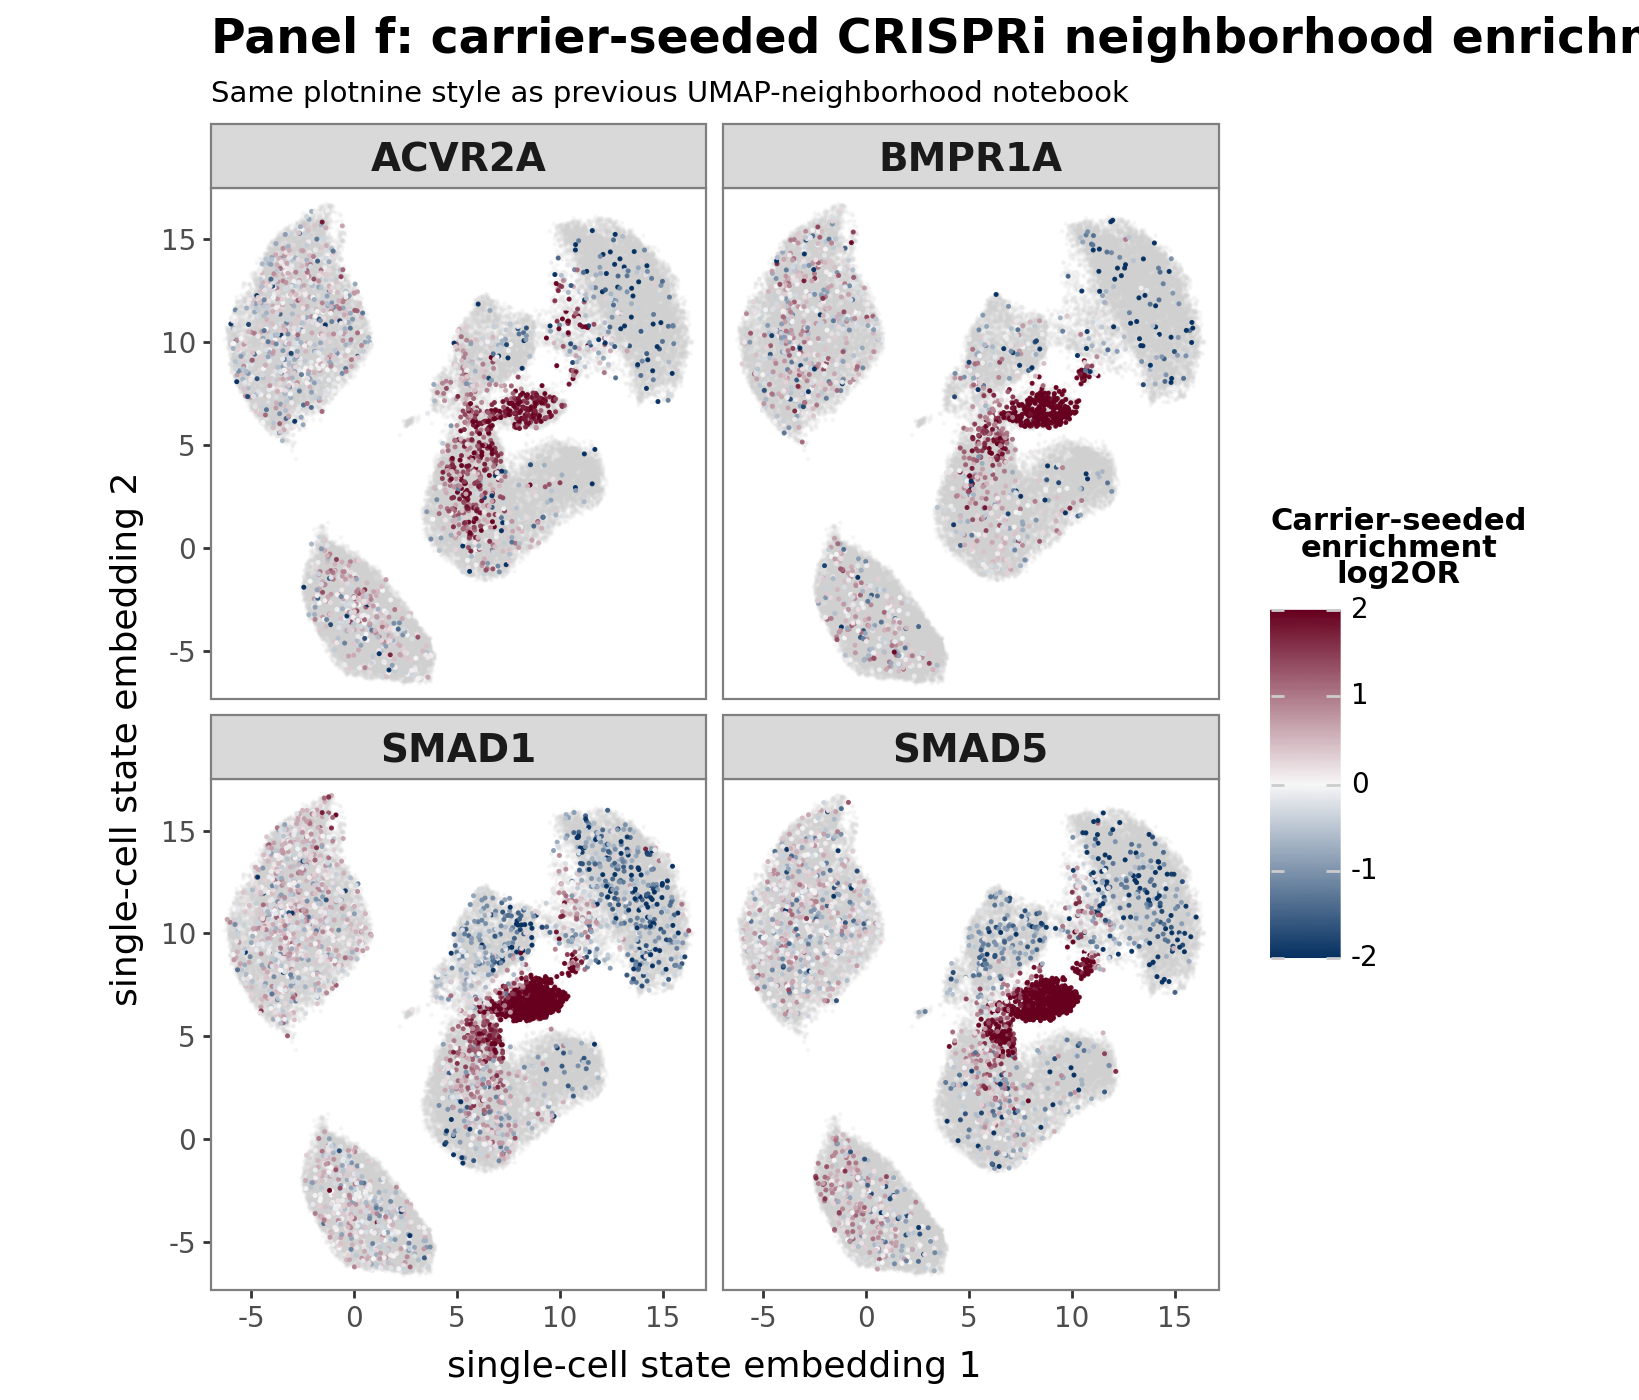

In [22]:

bg = pd.read_csv(OUTDIR / "all_days_background_cells_for_plotting.csv")

scores_plot, bg_plot, XLIM, YLIM = prepare_plot_sources(
    combined_scores,
    bg,
    cfg.PANEL_F_TARGETS + cfg.PANEL_J_TARGETS,
)

# Save plotting source tables for reproducibility
scores_plot.to_csv(OUTDIR / "source_carrier_seeded_scores_for_plotting_plotnine.csv", index=False)
bg_plot.to_csv(OUTDIR / "source_background_cells_sampled_for_plotting_plotnine.csv", index=False)

p_panel_f = make_faceted_panel_plotnine(
    scores_plot,
    bg_plot,
    cfg.PANEL_F_TARGETS,
    XLIM,
    YLIM,
    title="Panel f: carrier-seeded CRISPRi neighborhood enrichment",
    subtitle="Same plotnine style as previous UMAP-neighborhood notebook",
    style=cfg.PLOT_STYLE,
)

panel_f_paths = save_plotnine_panel(
    p_panel_f,
    out_prefix=f"panel_f_carrierseeded_neighborhood_grid_plotnine_{cfg.PLOT_STYLE}",
    width=cfg.FIGSIZE_FACET_4[0],
    height=cfg.FIGSIZE_FACET_4[1],
)
print(panel_f_paths)
p_panel_f


## 10. Plot panel j and display inline

{'png': PosixPath('fig3_carrierseeded_neighborhood_outputs/panel_j_carrierseeded_neighborhood_grid_plotnine_simple_color.png'), 'pdf': PosixPath('fig3_carrierseeded_neighborhood_outputs/panel_j_carrierseeded_neighborhood_grid_plotnine_simple_color.pdf'), 'svg': PosixPath('fig3_carrierseeded_neighborhood_outputs/panel_j_carrierseeded_neighborhood_grid_plotnine_simple_color.svg')}


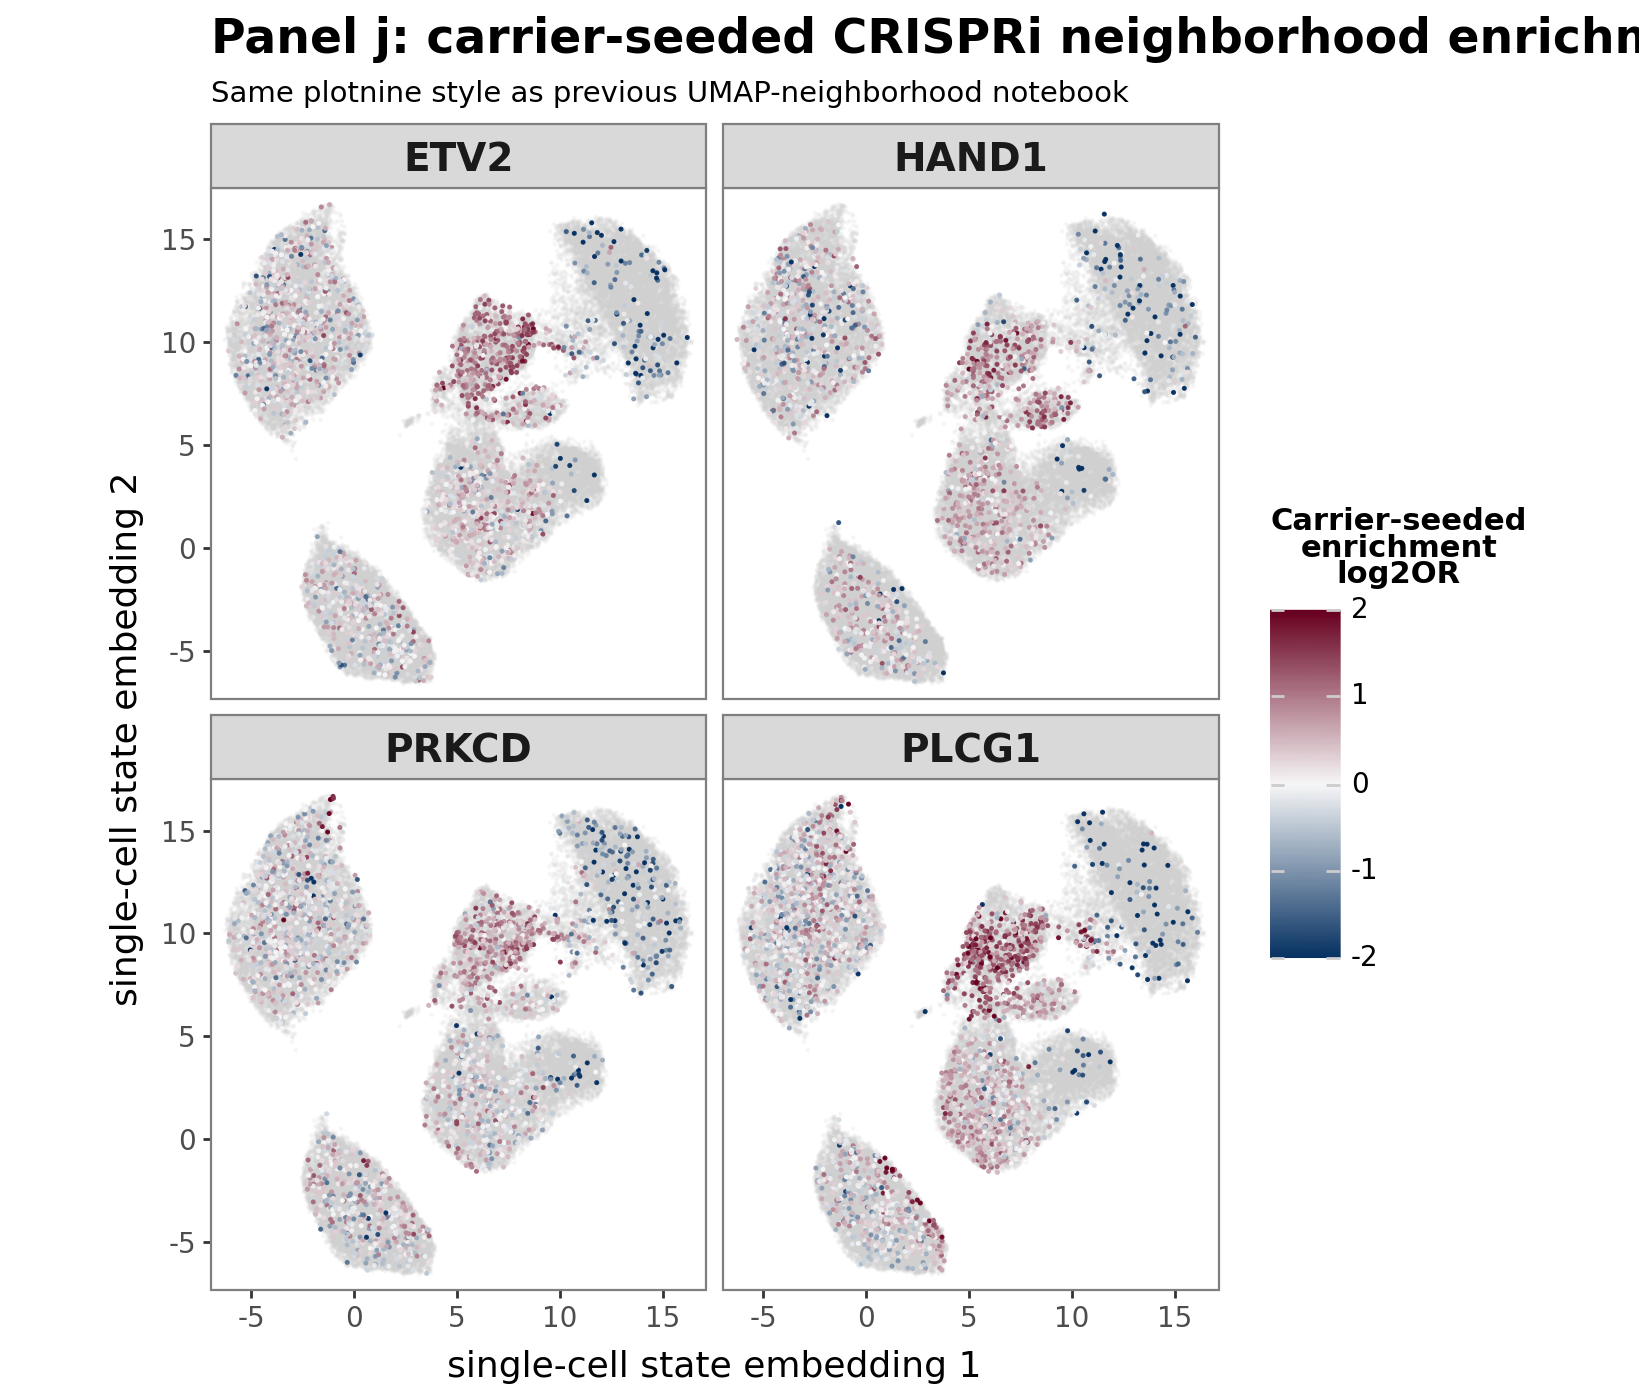

In [23]:

p_panel_j = make_faceted_panel_plotnine(
    scores_plot,
    bg_plot,
    cfg.PANEL_J_TARGETS,
    XLIM,
    YLIM,
    title="Panel j: carrier-seeded CRISPRi neighborhood enrichment",
    subtitle="Same plotnine style as previous UMAP-neighborhood notebook",
    style=cfg.PLOT_STYLE,
)

panel_j_paths = save_plotnine_panel(
    p_panel_j,
    out_prefix=f"panel_j_carrierseeded_neighborhood_grid_plotnine_{cfg.PLOT_STYLE}",
    width=cfg.FIGSIZE_FACET_4[0],
    height=cfg.FIGSIZE_FACET_4[1],
)
print(panel_j_paths)
p_panel_j


In [24]:
# Optional: save one full-size UMAP per target using the exact previous single-gene style
SAVE_SINGLE_TARGET_PLOTS = False

if SAVE_SINGLE_TARGET_PLOTS:
    single_targets = cfg.PANEL_F_TARGETS + cfg.PANEL_J_TARGETS
    for target in single_targets:
        p_single = make_single_umap_plotnine(scores_plot, bg_plot, target, XLIM, YLIM, style=cfg.PLOT_STYLE)
        paths = save_plotnine_panel(
            p_single,
            out_prefix=f"carrier_seeded_{target}_allDays_singleUMAP_plotnine_{cfg.PLOT_STYLE}",
            width=cfg.FIGSIZE_SINGLE[0],
            height=cfg.FIGSIZE_SINGLE[1],
        )
        print(target, paths)


## 11. Optional: inspect one target/day table

Use this to inspect whether enrichment is concentrated at D2/D3 or another day.

In [25]:

# Edit target below interactively
TARGET_TO_INSPECT = "NF2"  # or ACVR2A, BMPR1A, SMAD1, SMAD5, KDR, HAND1, PRKCD, PLCG1

if TARGET_TO_INSPECT in combined_scores["target"].unique():
    display(
        combined_scores.query("target == @TARGET_TO_INSPECT")
        .groupby(["day", "cell_type"])
        .agg(
            n_seed_cells=("seed_cell_id", "count"),
            median_log2_enrichment=("log2_local_enrichment", "median"),
            mean_log2_enrichment=("log2_local_enrichment", "mean"),
            n_fdr_by_day05=("fisher_fdr_by_day", lambda x: int(np.sum(x < 0.05)))
        )
        .reset_index()
        .sort_values(["day", "median_log2_enrichment"], ascending=[True, False])
    )
else:
    print(f"{TARGET_TO_INSPECT} not in combined_scores. Available targets:")
    print(sorted(combined_scores["target"].unique()))


NF2 not in combined_scores. Available targets:
['ACVR2A', 'BMPR1A', 'ETV2', 'HAND1', 'PLCG1', 'PRKCD', 'SMAD1', 'SMAD5']


## 12. Package outputs

In [26]:

zip_path = Path(f"{cfg.OUTDIR}.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for fn in OUTDIR.iterdir():
        if fn.is_file():
            z.write(fn, arcname=fn.name)
print("Saved outputs to", OUTDIR.resolve())
print("ZIP:", zip_path.resolve())


Saved outputs to /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/fig3_carrierseeded_neighborhood_plotnine_style_notebook_package/fig3_carrierseeded_neighborhood_outputs
ZIP: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/fig3_carrierseeded_neighborhood_plotnine_style_notebook_package/fig3_carrierseeded_neighborhood_outputs.zip
